# Oil and Gas Anomaly Detection — Section 4: Experiment 3

## Models with noise and with tuned hyperparameters

**Objective:** evaluate the same nine models under the same noise conditions as Experiment 2, using **tuned hyperparameter values**.

| Setting | Value |
|---|---|
| Input data | `final_datav1.csv` (single pre-assembled feature dataset, 117,401 rows × 129 columns after dropping `index`) |
| Noise injection | Gaussian, `mean=0.0`, `std=0.02`, then clipped to `[0, 1]`; applied to train and test sets after scaling |
| Hyperparameters | Fixed, tuned values written directly in the model constructors (see table below) |
| Split | 80 / 20, `random_state=42` |
| Normalisation | `StandardScaler` (fitted on training data) |
| Metrics | Accuracy, macro recall, macro F1, macro precision, MCC, confusion matrix, per-class ROC/AUC and macro AUC |

> **Important — scope of this notebook.** This notebook contains the *final, tuned* hyperparameter values only. The hyperparameter search itself (search spaces, number of trials, objective) is **not part of this notebook**: `optuna` is imported, but no Optuna study is created or run here. The decimal values (e.g. `learning_rate=0.07621005419696973`) are consistent with values found by an automated search such as Optuna, but the search code was not included in the project files.
>
> The input file `final_datav1.csv` is not produced by notebooks `01a` / `01b`; its construction is not included in the project files.

*Documentation (markdown cells and `#` comment lines) was added for publication; the original executable code and its outputs are unchanged.*

## 0. Environment setup

In [1]:
# ============================================================
# 0. ENVIRONMENT SETUP: LIBRARIES AND WARNING FILTERS
# ============================================================
# Import the data-handling, modelling, evaluation and plotting libraries.
# Note: some imported estimators (IsolationForest, AdaBoostClassifier,
# GaussianNB, OneClassSVM, LGBMClassifier, CatBoostClassifier) and the
# Optuna / cross-validation utilities are imported but not used below;
# the imports are kept unchanged to preserve the original environment.
import pandas as pd 
import numpy as np
import os
import glob

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import IsolationForest
from sklearn.ensemble import AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import OneClassSVM
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score, make_scorer, confusion_matrix, matthews_corrcoef

from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score , GroupKFold, GroupShuffleSplit,StratifiedGroupKFold
import optuna
import warnings
from sklearn.exceptions import ConvergenceWarning
# Ignorer uniquement les ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

## 1. Load the feature-engineered dataset

A single pre-assembled feature dataset (`final_datav1.csv`) is loaded and its `index` column is dropped. No de-duplication step is performed in this notebook.

In [2]:
# ============================================================
# 1. DATA LOADING
# ============================================================
# Load the pre-assembled feature dataset (128 features + `index` + `class`).
final_data = pd.read_csv('/kaggle/input/final-3wdataset/final_datav1.csv')

In [3]:
# Display the dataset.
final_data

,index,P-PDG_mean,P-PDG_std,P-PDG_min,P-PDG_max,P-PDG_median,P-PDG_range,P-PDG_q25,P-PDG_q75,P-PDG_iqr,...,QGL_q75,QGL_iqr,QGL_mad,QGL_mean_abs,QGL_rms,QGL_energy,QGL_skew,QGL_kurtosis,QGL_zero_crossings,class
0,0,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
1,1,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
2,2,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
3,3,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
4,4,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117396,165104,1.715209e+07,1519.275871,1.714959e+07,1.715460e+07,1.715209e+07,5010.000000,1.715084e+07,1.715334e+07,2504.375000,...,4.365014,0.028755,0.014873,4.350611,4.350645,567.843367,-0.012862,-1.199806,0.0,9
117397,165105,1.715726e+07,1515.598171,1.715477e+07,1.715976e+07,1.715726e+07,4990.000000,1.715601e+07,1.715851e+07,2495.000000,...,4.304973,0.029790,0.015409,4.290051,4.290088,552.145641,-0.012840,-1.199792,0.0,9
117398,165106,1.716246e+07,1537.051439,1.715994e+07,1.716500e+07,1.716245e+07,5060.000000,1.716119e+07,1.716372e+07,2532.500000,...,4.242770,0.041188,0.020734,4.221550,4.221617,534.661449,-0.135992,-1.261894,0.0,9
117399,165107,1.716770e+07,1526.832665,1.716517e+07,1.717016e+07,1.716771e+07,4992.499999,1.716645e+07,1.716898e+07,2526.874999,...,4.155836,0.043605,0.022554,4.133993,4.134075,512.717264,-0.013416,-1.199885,0.0,9


In [4]:
# Drop the stored row-index column.
final_data.drop(columns=['index'], inplace=True)

In [5]:
# Display the final modelling dataset.
final_data

,P-PDG_mean,P-PDG_std,P-PDG_min,P-PDG_max,P-PDG_median,P-PDG_range,P-PDG_q25,P-PDG_q75,P-PDG_iqr,P-PDG_mad,...,QGL_q75,QGL_iqr,QGL_mad,QGL_mean_abs,QGL_rms,QGL_energy,QGL_skew,QGL_kurtosis,QGL_zero_crossings,class
0,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
1,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
2,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
3,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
4,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117396,1.715209e+07,1519.275871,1.714959e+07,1.715460e+07,1.715209e+07,5010.000000,1.715084e+07,1.715334e+07,2504.375000,1294.083333,...,4.365014,0.028755,0.014873,4.350611,4.350645,567.843367,-0.012862,-1.199806,0.0,9
117397,1.715726e+07,1515.598171,1.715477e+07,1.715976e+07,1.715726e+07,4990.000000,1.715601e+07,1.715851e+07,2495.000000,1291.333333,...,4.304973,0.029790,0.015409,4.290051,4.290088,552.145641,-0.012840,-1.199792,0.0,9
117398,1.716246e+07,1537.051439,1.715994e+07,1.716500e+07,1.716245e+07,5060.000000,1.716119e+07,1.716372e+07,2532.500000,1309.166667,...,4.242770,0.041188,0.020734,4.221550,4.221617,534.661449,-0.135992,-1.261894,0.0,9
117399,1.716770e+07,1526.832665,1.716517e+07,1.717016e+07,1.716771e+07,4992.499999,1.716645e+07,1.716898e+07,2526.874999,1303.166666,...,4.155836,0.043605,0.022554,4.133993,4.134075,512.717264,-0.013416,-1.199885,0.0,9


## 2. Train-test split, normalisation and noise injection

* Features `X` = the 128 statistical features; target `Y` = `class` (10 classes, 0–9).
* **Split:** `train_test_split(test_size=0.2, random_state=42)` — 80 % training / 20 % test, random (not stratified).
* **Normalisation:** `StandardScaler` fitted on the training set only, then applied to the test set.

In [6]:
# ============================================================
# 2. TRAIN-TEST SPLIT, NORMALISATION AND NOISE INJECTION
# ============================================================
# Separate the 128 features (X) from the class label (Y).
X = final_data.drop('class', axis = 1)
Y = final_data['class']

In [7]:
# Random 80/20 train-test split with a fixed seed (random_state=42).
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

# Function to add noise 

### Noise injection (same function and parameters as Experiment 2)

`add_gaussian_noise(X, mean=0.0, std=0.02)` adds zero-mean Gaussian noise with standard deviation **0.02** to every feature value and then clips the result to the interval **[0, 1]** (`np.clip(X + noise, 0., 1.)`).

It is applied **after** standardisation, independently to the training set and to the test set. No random seed is set for `np.random`, so the noise realisation differs between runs.

In [8]:
# ============================================================
# NOISE INJECTION FUNCTION
# ============================================================
# Add Gaussian noise N(mean, std^2) to every element of X, then clip the
# noisy values to [0, 1]. Defaults: mean=0.0, std=0.02. No seed is set.
def add_gaussian_noise(X, mean=0.0, std=0.02):
    noise = np.random.normal(loc=mean, scale=std, size=X.shape)
    return np.clip(X + noise, 0., 1.)

In [9]:
# Standardise features: fit the scaler on the training set, apply it to both sets.
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
# Inject Gaussian noise (std=0.02, clipped to [0, 1]) into the scaled training and test sets.
X_train = add_gaussian_noise(X_train, std=0.02)
X_test  = add_gaussian_noise(X_test, std=0.02)

## 3. Model training and evaluation (tuned hyperparameters)

| # | Model | Hyperparameters used |
|---|---|---|
| 1 | XGBoost | `n_estimators=185, max_depth=10, learning_rate=0.07621005419696973, subsample=0.8579402483438301` |
| 2 | SVC | `C=65.76241489919478, kernel='rbf', gamma='scale', degree=4, probability=True` |
| 3 | k-NN | `n_neighbors=16, weights='distance', algorithm='brute', metric='manhattan', p=1` |
| 4 | Decision Tree | `criterion='entropy', max_depth=17, min_samples_split=8, min_samples_leaf=8, random_state=42` |
| 5 | Logistic Regression | `C=81.40911334949928, penalty='l2', fit_intercept=True, max_iter=339, tol=1.3444367682112582e-05, solver='lbfgs', multi_class='auto', random_state=42` |
| 6 | Random Forest | `n_estimators=168, max_depth=20, min_samples_split=3, min_samples_leaf=6, bootstrap=False, random_state=42` |
| 7 | Lasso (L1) logistic regression | `penalty='l1', solver='saga', C=3.167281368521384, max_iter=935, random_state=42` |
| 8 | Ridge (L2) logistic regression | `penalty='l2', solver='newton-cg', C=7.249509828331678, max_iter=786, random_state=42` |
| 9 | Elastic-Net logistic regression | `penalty='elasticnet', solver='saga', l1_ratio=0.26412068295144886, C=0.32421631749317886, max_iter=797, random_state=42` |

For each model: initialise → `fit` on the noisy training set → `predict` on the noisy test set → accuracy, macro recall, macro F1, macro precision, MCC and confusion matrix → confusion-matrix plot.

# XGboost

In [11]:
# ============================================================
# 3. MODEL TRAINING AND EVALUATION (TUNED HYPERPARAMETERS)
# ============================================================
# 3.1 XGBoost
# Tuned values: 185 trees, max depth 10, learning rate ~0.0762, row subsampling ~0.858.
# Initialise the XGBoost classifier.
model1 = XGBClassifier(
    n_estimators=185,
    max_depth=10,
    learning_rate=0.07621005419696973,
    subsample=0.8579402483438301
)

In [12]:
# Train XGBoost on the (scaled) training set.
model1.fit(X_train,y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.07621005419696973,
              max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=10, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=185, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)

In [13]:
# Predict class labels for the test set with XGBoost.
pre_xgb = model1.predict(X_test)

In [14]:
# Compute the evaluation metrics on the held-out test set:
# accuracy, macro-averaged recall / F1 / precision, Matthews correlation
# coefficient (MCC) and the confusion matrix.
# NOTE (implementation detail, kept as in the original study): every metric
# is called as metric(predictions, y_test), i.e. predictions occupy the
# first argument (scikit-learn's `y_true` position). Accuracy, macro-F1 and
# MCC are symmetric; for precision, recall and the confusion matrix the
# argument order matters. See README.md -> 'Implementation notes'.
accuracy = accuracy_score(pre_xgb,y_test)
recall=recall_score(pre_xgb,y_test, average='macro')
f1=f1_score(pre_xgb,y_test, average='macro')
precision=precision_score(pre_xgb,y_test, average='macro')
mcc = matthews_corrcoef(pre_xgb,y_test)
cf= confusion_matrix(pre_xgb,y_test)

In [15]:
# Report the XGBoost configuration and its test-set metrics.
print(model1)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.07621005419696973,
              max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=10, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=185, n_jobs=None,
              num_parallel_tree=None, objective='multi:softprob', ...)
accuracy is :  0.9893105063668498 recall is :  0.9887658291493455 f1 is : 0.9778326958987004
precision is 0.9699592310332065
MCC is  0.9876001071077241


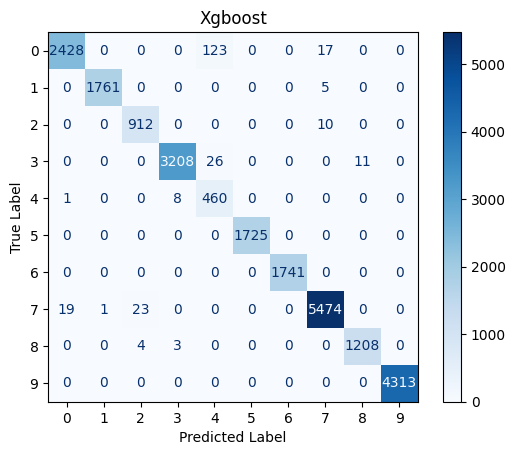

In [16]:
# Visualise and save the XGBoost confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Xgboost")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_xgboost.png", dpi=300, bbox_inches='tight')
plt.show()

# SVC

In [17]:
# 3.2 Support Vector Machine (SVC)
# Tuned values: RBF kernel, C ~65.76, gamma='scale'. `degree` only affects
# the polynomial kernel. probability=True enables predict_proba().
# Initialise the Support Vector Machine (SVC) classifier.
model2 =  SVC(
    C=65.76241489919478,
    kernel='rbf',
    gamma='scale',
    degree=4,
    probability=True  # for the ROC curve or predict_proba()
)

In [18]:
# Train Support Vector Machine (SVC) on the (scaled) training set.
model2.fit(X_train,y_train)

SVC(C=65.76241489919478, degree=4, probability=True)

In [19]:
# Predict class labels for the test set with Support Vector Machine (SVC).
pre_svc = model2.predict(X_test)

In [20]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_svc,y_test)
recall = recall_score(pre_svc,y_test, average = 'macro')
f1=f1_score(pre_svc,y_test, average='macro')
precision=precision_score(pre_svc,y_test, average='macro')
mcc = matthews_corrcoef(pre_svc,y_test)
cf= confusion_matrix(pre_svc,y_test)

In [22]:
# Report the Support Vector Machine (SVC) configuration and its test-set metrics.
print(model2)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

SVC(C=65.76241489919478, degree=4, probability=True)
accuracy is :  0.9838592904901835 recall is :  0.9852865883277975 f1 is : 0.9663265930581535
precision is 0.9544717852139192
MCC is  0.981305036554661


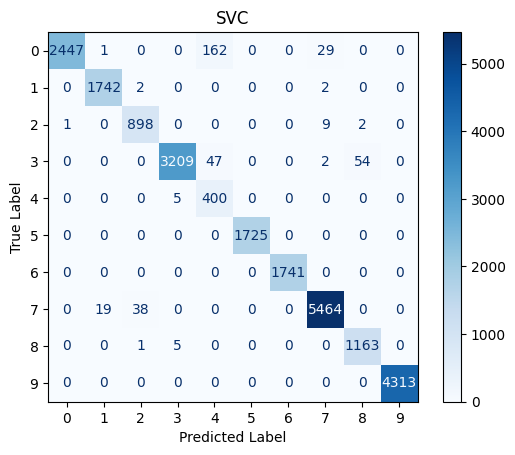

In [21]:
# Visualise and save the Support Vector Machine (SVC) confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("SVC")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_svc.png", dpi=300, bbox_inches='tight')
plt.show()

# KNN

In [23]:
# 3.3 k-Nearest Neighbors
# Tuned values: 16 neighbours, distance weighting, brute-force search, Manhattan (L1) distance.
# Initialise the k-Nearest Neighbors classifier.
model3= KNeighborsClassifier(
    n_neighbors=16,
    weights='distance',
    algorithm='brute',
    metric='manhattan',
    p=1
)

In [24]:
# Train k-Nearest Neighbors on the (scaled) training set.
model3.fit(X_train,y_train)

KNeighborsClassifier(algorithm='brute', metric='manhattan', n_neighbors=16, p=1,
                     weights='distance')

In [25]:
# Predict class labels for the test set with k-Nearest Neighbors.
pre_knn = model3.predict(X_test)

In [26]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_knn,y_test)
recall = recall_score(pre_knn,y_test, average = 'macro')
f1=f1_score(pre_knn,y_test, average='macro')
precision=precision_score(pre_knn,y_test, average='macro')
mcc = matthews_corrcoef(pre_knn,y_test)
cf= confusion_matrix(pre_knn,y_test)

In [27]:
# Report the k-Nearest Neighbors configuration and its test-set metrics.
print(model3)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

KNeighborsClassifier(algorithm='brute', metric='manhattan', n_neighbors=16, p=1,
                     weights='distance')
accuracy is :  0.9819854350325795 recall is :  0.9785582644620667 f1 is : 0.964406840553204
precision is 0.9546386978995682
MCC is  0.979101264845835


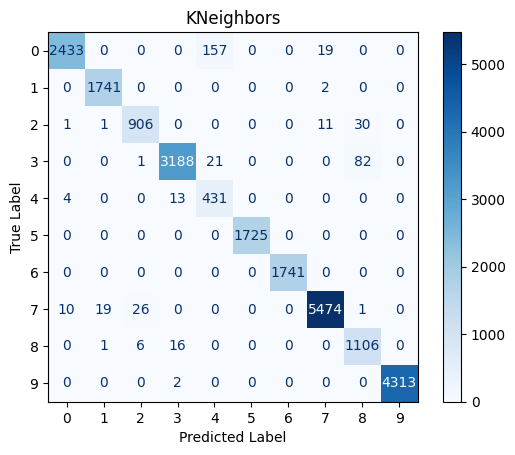

In [28]:
# Visualise and save the k-Nearest Neighbors confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("KNeighbors")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_knn.png", dpi=300, bbox_inches='tight')
plt.show()

# decision Tree

In [29]:
# 3.4 Decision Tree
# Tuned values: entropy criterion, max depth 17, min 8 samples to split and per leaf.
# Initialise the Decision Tree classifier.
model4= DecisionTreeClassifier(
    criterion='entropy',
    max_depth=17,
    min_samples_split=8,
    min_samples_leaf=8,
    random_state=42
)

In [30]:
# Train Decision Tree on the (scaled) training set.
model4.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=17, min_samples_leaf=8,
                       min_samples_split=8, random_state=42)

In [31]:
# Predict class labels for the test set with Decision Tree.
pre_dtree = model4.predict(X_test)

In [32]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_dtree,y_test)
recall = recall_score(pre_dtree,y_test, average = 'macro')
f1=f1_score(pre_dtree,y_test, average='macro')
precision=precision_score(pre_dtree,y_test, average='macro')
mcc = matthews_corrcoef(pre_dtree,y_test)
cf= confusion_matrix(pre_dtree,y_test)

In [33]:
# Report the Decision Tree configuration and its test-set metrics.
print(model4)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

DecisionTreeClassifier(criterion='entropy', max_depth=17, min_samples_leaf=8,
                       min_samples_split=8, random_state=42)
accuracy is :  0.9850091563391679 recall is :  0.9802219169283279 f1 is : 0.9706416963600869
precision is 0.9640776327478662
MCC is  0.9826120738294775


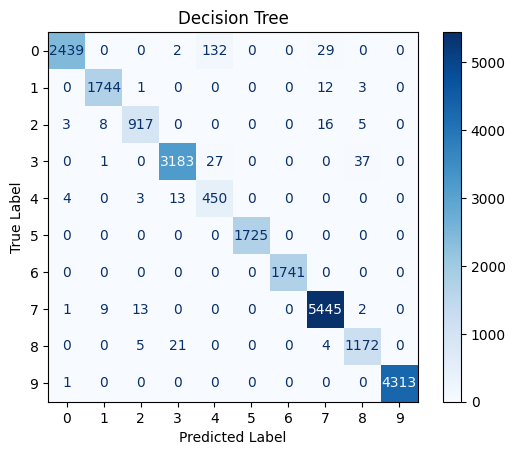

In [34]:
# Visualise and save the Decision Tree confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_dtree.png", dpi=300, bbox_inches='tight')
plt.show()

# Logistic Regression 

In [35]:
# 3.5 Logistic Regression
# Tuned values: L2 penalty, C ~81.41, lbfgs solver, max 339 iterations, tol ~1.34e-05.
# Initialise the Logistic Regression classifier.
model5= LogisticRegression(
    C=81.40911334949928,
    penalty='l2',
    fit_intercept=True,
    max_iter=339,
    tol=1.3444367682112582e-05,
    solver='lbfgs',       
    multi_class='auto',
    random_state=42
)

In [36]:
# Train Logistic Regression on the (scaled) training set.
model5.fit(X_train,y_train)

LogisticRegression(C=81.40911334949928, max_iter=339, random_state=42,
                   tol=1.3444367682112582e-05)

In [37]:
# Predict class labels for the test set with Logistic Regression.
pre_lg = model5.predict(X_test)

In [38]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_lg,y_test)
recall = recall_score(pre_lg,y_test, average = 'macro')
f1=f1_score(pre_lg,y_test, average='macro')
precision=precision_score(pre_lg,y_test, average='macro')
mcc = matthews_corrcoef(pre_lg,y_test)
cf= confusion_matrix(pre_lg,y_test)

In [39]:
# Report the Logistic Regression configuration and its test-set metrics.
print(model5)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

LogisticRegression(C=81.40911334949928, max_iter=339, random_state=42,
                   tol=1.3444367682112582e-05)
accuracy is :  0.9710404156552106 recall is :  0.968666459488485 f1 is : 0.9467988566033496
precision is 0.9319076708942606
MCC is  0.9663577644931312


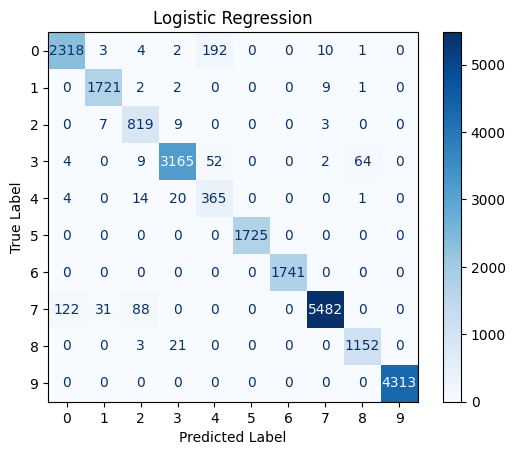

In [40]:
# Visualise and save the Logistic Regression confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_lg.png", dpi=300, bbox_inches='tight')
plt.show()

# Random Forest

In [41]:
# 3.6 Random Forest
# Tuned values: 168 trees, max depth 20, min 3 samples to split, min 6 per leaf, no bootstrap.
# Initialise the Random Forest classifier.
model6= RandomForestClassifier(
    n_estimators=168,
    max_depth=20,
    min_samples_split=3,
    min_samples_leaf=6,
    bootstrap=False,
    random_state=42
)

In [42]:
# Train Random Forest on the (scaled) training set.
model6.fit(X_train,y_train)

RandomForestClassifier(bootstrap=False, max_depth=20, min_samples_leaf=6,
                       min_samples_split=3, n_estimators=168, random_state=42)

In [43]:
# Predict class labels for the test set with Random Forest.
pre_rf = model6.predict(X_test)

In [44]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_rf,y_test)
recall = recall_score(pre_rf,y_test, average = 'macro')
f1=f1_score(pre_rf,y_test, average='macro')
precision=precision_score(pre_rf,y_test, average='macro')
mcc = matthews_corrcoef(pre_rf,y_test)
cf= confusion_matrix(pre_rf,y_test)

In [47]:
# Report the Random Forest configuration and its test-set metrics.
print(model6)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

RandomForestClassifier(bootstrap=False, max_depth=20, min_samples_leaf=6,
                       min_samples_split=3, n_estimators=168, random_state=42)
accuracy is :  0.9832204761296367 recall is :  0.9885029577802079 f1 is : 0.9688125047332827
precision is 0.955176048468554
MCC is  0.9805334598672927


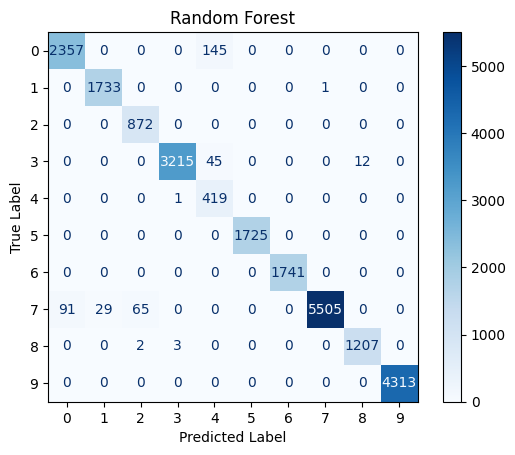

In [45]:
# Visualise and save the Random Forest confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_matrix_rf.png", dpi=300, bbox_inches='tight')
plt.show()

# satistical model

# Lasso

In [11]:
# ============================================================
# 3.7-3.9 STATISTICAL MODELS: REGULARISED LOGISTIC REGRESSION
# ============================================================
# 3.7 Lasso (L1) logistic regression
# Tuned values: L1 penalty, saga solver, C ~3.167, max 935 iterations.
# Initialise the Lasso (L1) logistic regression classifier.
lasso_model = LogisticRegression(penalty='l1', solver='saga', C=3.167281368521384 ,max_iter=935, random_state=42)

In [12]:
# Train Lasso (L1) logistic regression on the (scaled) training set.
lasso_model.fit(X_train,y_train)

LogisticRegression(C=3.167281368521384, max_iter=935, penalty='l1',
                   random_state=42, solver='saga')

In [13]:
# Predict class labels for the test set with Lasso (L1) logistic regression.
pre_lasso = lasso_model.predict(X_test)

In [14]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_lasso,y_test)
recall = recall_score(pre_lasso,y_test, average = 'macro')
f1=f1_score(pre_lasso,y_test, average='macro')
precision=precision_score(pre_lasso,y_test, average='macro')
mcc = matthews_corrcoef(pre_lasso,y_test)
cf= confusion_matrix(pre_lasso,y_test)

In [15]:
# Report the Lasso (L1) logistic regression configuration and its test-set metrics.
print(lasso_model)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

LogisticRegression(C=3.167281368521384, max_iter=935, penalty='l1',
                   random_state=42, solver='saga')
accuracy is :  0.9704867765427366 recall is :  0.9666907226807971 f1 is : 0.9458165735547016
precision is 0.9309691758485938
MCC is  0.9657108544655236


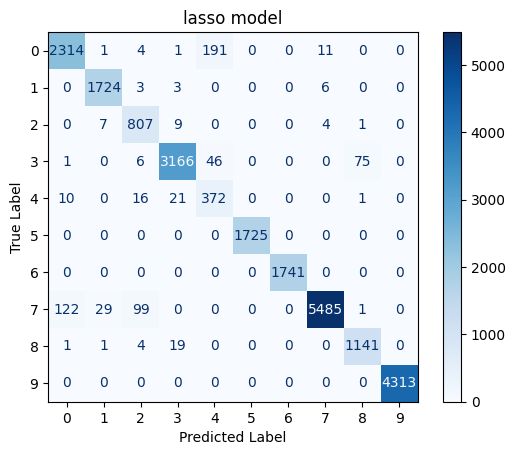

In [16]:
# Visualise and save the Lasso (L1) logistic regression confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("lasso model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_lasso")

# ridge

In [17]:
# 3.8 Ridge (L2) logistic regression
# Tuned values: L2 penalty, newton-cg solver, C ~7.250, max 786 iterations.
# Initialise the Ridge (L2) logistic regression classifier.
ridge_model = LogisticRegression(penalty='l2', solver='newton-cg', C=7.249509828331678, max_iter=786 ,random_state=42)

In [18]:
# Train Ridge (L2) logistic regression on the (scaled) training set.
ridge_model.fit(X_train,y_train)

LogisticRegression(C=7.249509828331678, max_iter=786, random_state=42,
                   solver='newton-cg')

In [19]:
# Predict class labels for the test set with Ridge (L2) logistic regression.
pre_ridge = ridge_model.predict(X_test)

In [20]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_ridge,y_test)
recall = recall_score(pre_ridge,y_test, average = 'macro')
f1=f1_score(pre_ridge,y_test, average='macro')
precision=precision_score(pre_ridge,y_test, average='macro')
mcc = matthews_corrcoef(pre_ridge,y_test)
cf= confusion_matrix(pre_ridge,y_test)

In [21]:
# Report the Ridge (L2) logistic regression configuration and its test-set metrics.
print(ridge_model)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

LogisticRegression(C=7.249509828331678, max_iter=786, random_state=42,
                   solver='newton-cg')
accuracy is :  0.968740683957242 recall is :  0.9655677222396465 f1 is : 0.9425759796728471
precision is 0.9267364052422525
MCC is  0.9636848655512666


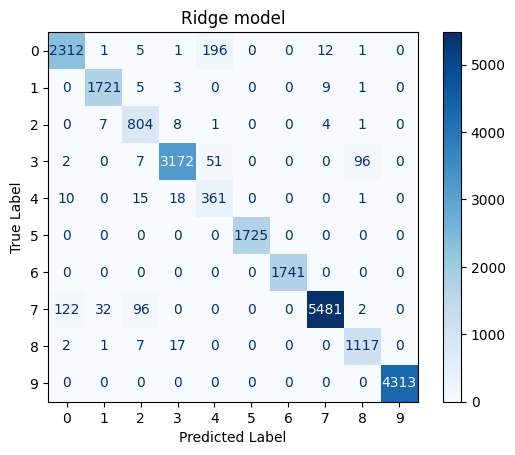

In [22]:
# Visualise and save the Ridge (L2) logistic regression confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("Ridge model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_Ridge")

# elastic

In [23]:
# 3.9 Elastic-Net logistic regression
# Tuned values: Elastic-Net penalty, saga solver, l1_ratio ~0.264, C ~0.324, max 797 iterations.
# Initialise the Elastic-Net logistic regression classifier.
elastic_model = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.26412068295144886, C=0.32421631749317886, max_iter=797 ,random_state=42)

In [24]:
# Train Elastic-Net logistic regression on the (scaled) training set.
elastic_model.fit(X_train,y_train)

LogisticRegression(C=0.32421631749317886, l1_ratio=0.26412068295144886,
                   max_iter=797, penalty='elasticnet', random_state=42,
                   solver='saga')

In [25]:
# Predict class labels for the test set with Elastic-Net logistic regression.
pre_elastic = elastic_model.predict(X_test)

In [26]:
# Compute accuracy, macro recall / F1 / precision, MCC and the confusion
# matrix on the test set (same argument order as above: predictions first).
accuracy = accuracy_score(pre_elastic,y_test)
recall = recall_score(pre_elastic,y_test, average = 'macro')
f1=f1_score(pre_elastic,y_test, average='macro')
precision=precision_score(pre_elastic,y_test, average='macro')
mcc = matthews_corrcoef(pre_elastic,y_test)
cf= confusion_matrix(pre_elastic,y_test)

In [27]:
# Report the Elastic-Net logistic regression configuration and its test-set metrics.
print(elastic_model)
print('accuracy is : ',accuracy,'recall is : ',recall,'f1 is :',f1)
print('precision is',precision)
print('MCC is ',mcc)

LogisticRegression(C=0.32421631749317886, l1_ratio=0.26412068295144886,
                   max_iter=797, penalty='elasticnet', random_state=42,
                   solver='saga')
accuracy is :  0.9567735616029982 recall is :  0.951261909354867 f1 is : 0.9205721762604353
precision is 0.9011866499376786
MCC is  0.9498263400529142


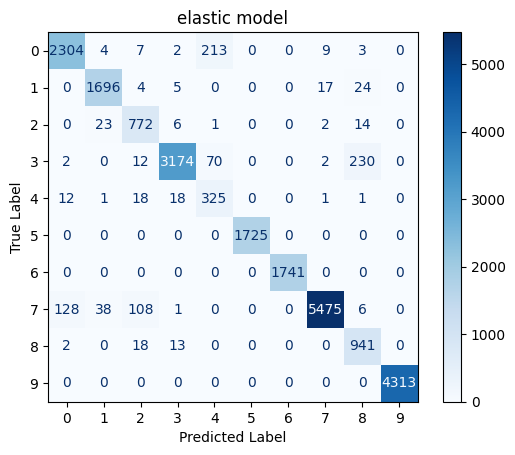

In [28]:
# Visualise and save the Elastic-Net logistic regression confusion matrix (matrix `cf` computed above).
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cf)
disp.plot(cmap=plt.cm.Blues)

plt.title("elastic model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.savefig("confusion_elastic")

## ROC curves and macro AUC

For each model, test labels and predicted labels are one-hot encoded over the 10 classes and one-vs-rest ROC curves / AUC values are computed per class; the macro-averaged AUC is printed and each figure is saved as a PNG.

# Roc 

lasso_model Macro AUC: 0.964
ridge_model Macro AUC: 0.962
elastic_model Macro AUC: 0.948


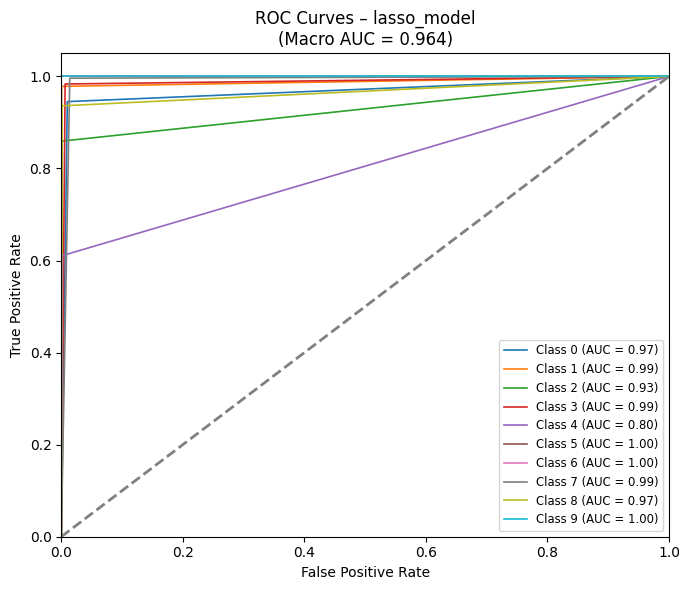

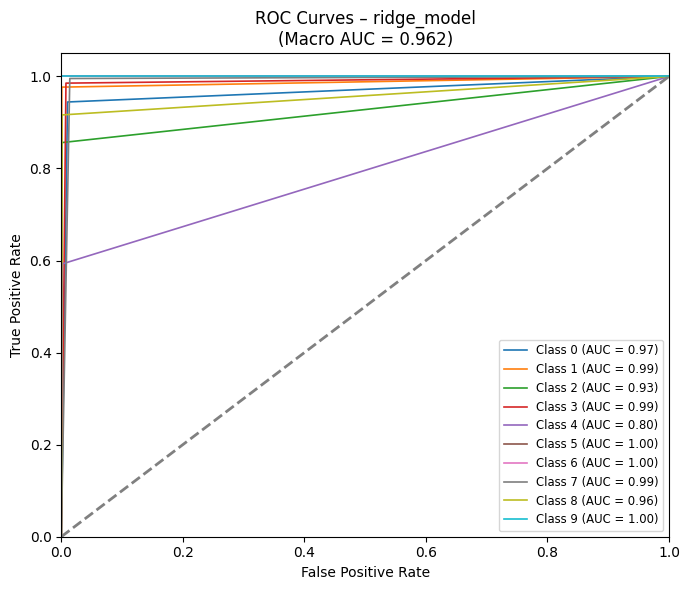

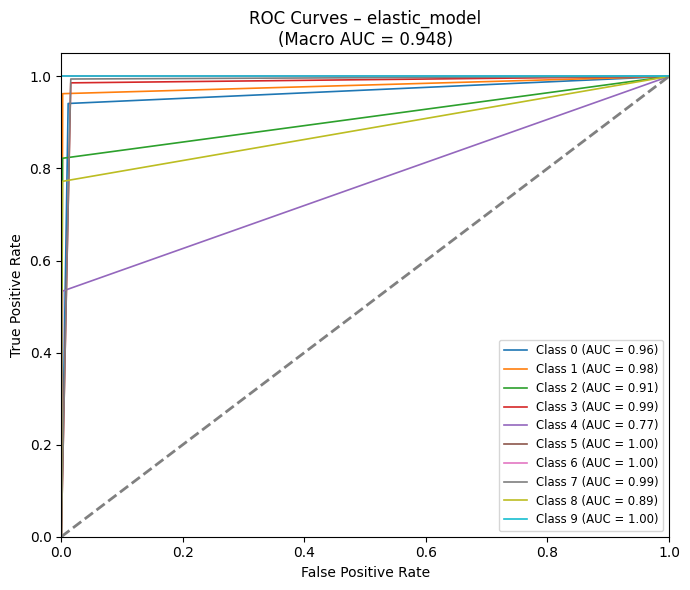

In [29]:
# ============================================================
# ROC CURVES AND MACRO AUC - STATISTICAL (REGULARISED LOGISTIC) MODELS
# ============================================================
# For each model, the test labels and the predicted class labels are
# one-hot encoded (label_binarize, 10 classes) and a one-vs-rest ROC curve
# and AUC are computed per class; the macro-averaged AUC is printed and
# each figure is saved as a PNG file.
# Note: the ROC curves are built from hard class predictions (not from
# predicted probabilities), as in the original study.
# statistical
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Example data structure
results = {
    "lasso_model": pre_lasso,
    "ridge_model": pre_ridge,
    "elastic_model": pre_elastic
}

n_classes = 10
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

for name, y in results.items():
    # Ensure predictions are probabilities for each class (shape: [n_samples, n_classes])

      # If predictions are class labels, convert to one-hot
    y_bin = label_binarize(y, classes=np.arange(n_classes))


    fpr, tpr, auc_score = {}, {}, {}

    plt.figure(figsize=(7, 6))

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_bin[:, i])
        auc_score[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], lw=1.2, label=f"Class {i} (AUC = {auc_score[i]:.2f})")

    # Macro-average AUC
    auc_macro = roc_auc_score(y_test_bin, y_bin, average="macro")
    print(f"{name} Macro AUC: {auc_macro:.3f}")

    # Diagonal (random guess)
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

    # Customize plot
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curves – {name}\n(Macro AUC = {auc_macro:.3f})')
    plt.legend(loc='lower right', fontsize='small')

    plt.tight_layout()
    plt.savefig(f"ROC_NO_NOISY_AND_NO_HYPERPARAMETER_{name.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
plt.show()#

XGBoost Macro AUC: 0.984
Support Vector Machine Macro AUC: 0.976
k-Nearest Neighbors Macro AUC: 0.976
Decision Tree Macro AUC: 0.981
Logistic Regression Macro AUC: 0.964
Random Forest Macro AUC: 0.977


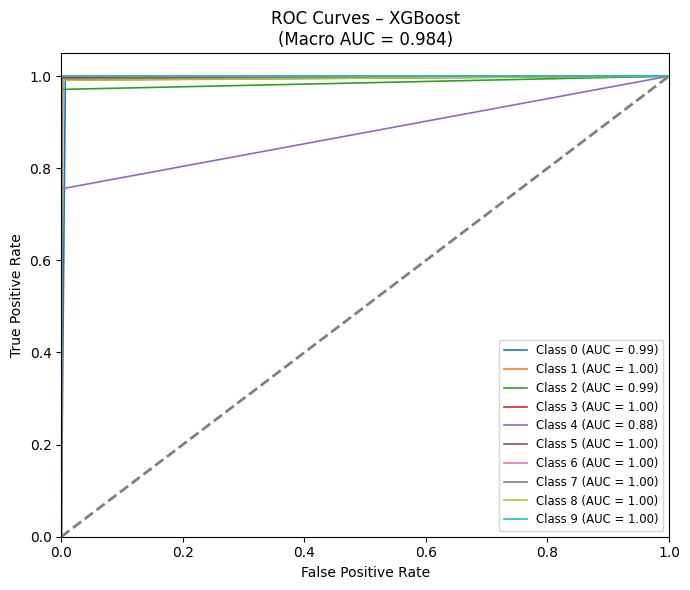

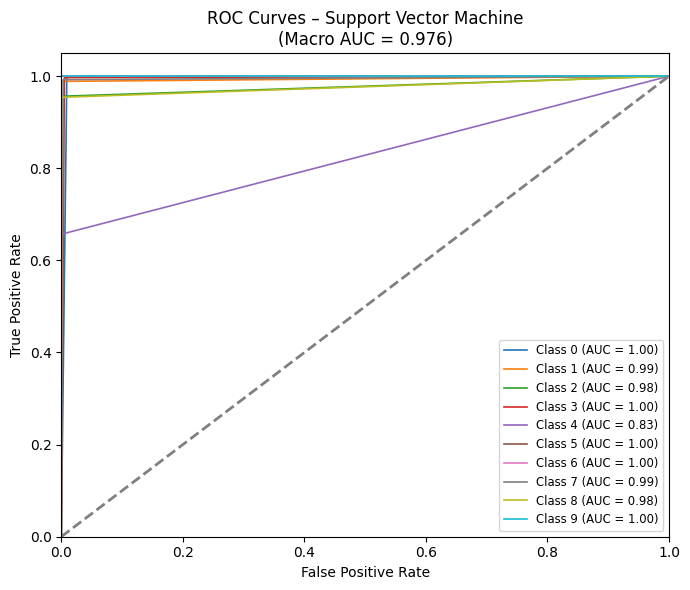

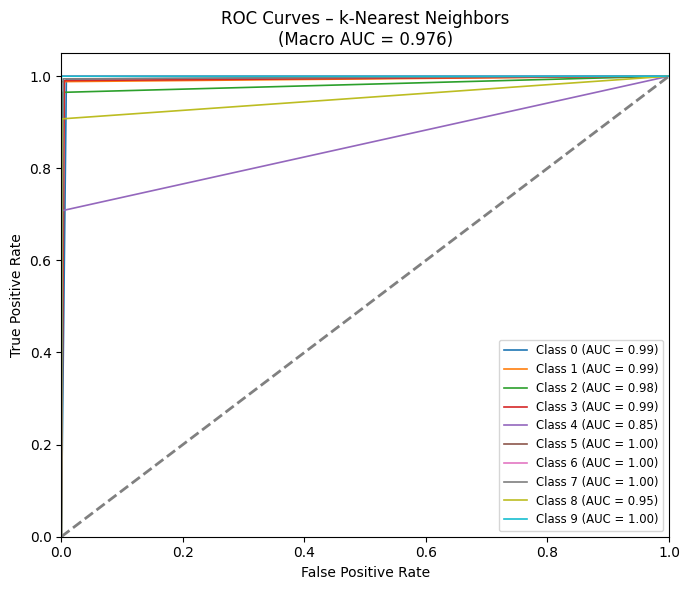

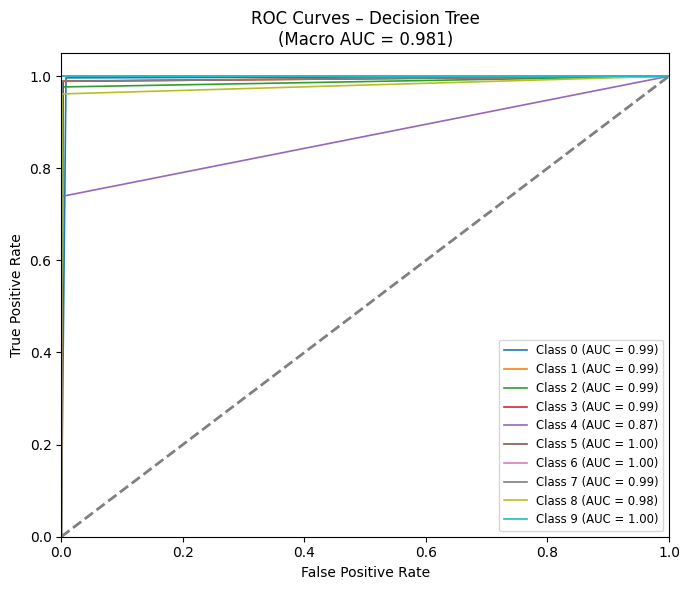

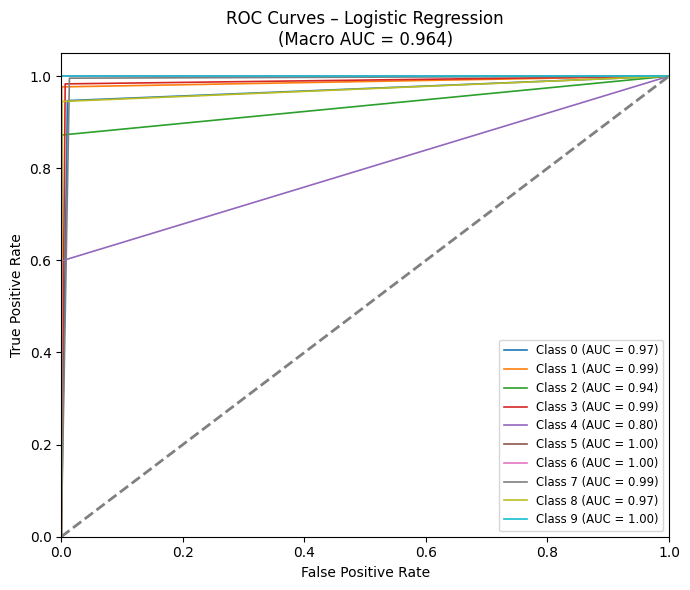

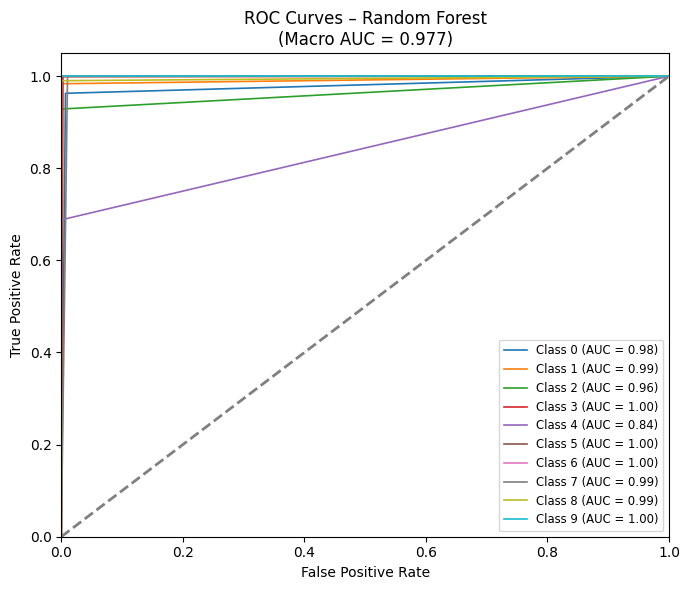

In [46]:
# ============================================================
# ROC CURVES AND MACRO AUC - MACHINE LEARNING MODELS
# ============================================================
# Same one-vs-rest ROC / macro-AUC procedure as above, applied to the six
# machine learning classifiers (hard class predictions, 10 classes).
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Example data structure
results = {
    "XGBoost": pre_xgb,
    "Support Vector Machine": pre_svc,
    "k-Nearest Neighbors": pre_knn,
    "Decision Tree": pre_dtree,
    "Logistic Regression": pre_lg,
    "Random Forest": pre_rf
}

n_classes = 10
y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

for name, y in results.items():
    # Ensure predictions are probabilities for each class (shape: [n_samples, n_classes])

      # If predictions are class labels, convert to one-hot
    y_bin = label_binarize(y, classes=np.arange(n_classes))


    fpr, tpr, auc_score = {}, {}, {}

    plt.figure(figsize=(7, 6))

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_bin[:, i])
        auc_score[i] = auc(fpr[i], tpr[i])
        plt.plot(fpr[i], tpr[i], lw=1.2, label=f"Class {i} (AUC = {auc_score[i]:.2f})")

    # Macro-average AUC
    auc_macro = roc_auc_score(y_test_bin, y_bin, average="macro")
    print(f"{name} Macro AUC: {auc_macro:.3f}")

    # Diagonal (random guess)
    plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

    # Customize plot
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curves – {name}\n(Macro AUC = {auc_macro:.3f})')
    plt.legend(loc='lower right', fontsize='small')

    plt.tight_layout()
    plt.savefig(f"ROC_with_NOISY_AND_HYPERPARAMETER_{name.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
plt.show()